In [2]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import requests
import zipfile
import io

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

In [4]:
url = "https://www.kaggle.com/api/v1/datasets/download/clmentbisaillon/fake-and-real-news-dataset"

response = requests.get(url)
response.raise_for_status()

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [5]:
with zipfile.ZipFile(io.BytesIO(response.content)) as zip_file:
    zip_file.extractall("/content/fake_news")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [6]:
fake = pd.read_csv("/content/fake_news/Fake.csv")
real = pd.read_csv("/content/fake_news/True.csv")

print("Fake News Dataset:")
display(fake.head())

print("Real News Dataset:")
display(real.head())

Fake News Dataset:


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


Real News Dataset:


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [7]:
fake["label"] = 0
real["label"] = 1

print("Labels added successfully!")

Labels added successfully!


In [8]:
df = pd.concat([fake, real], axis=0)

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Combined Dataset Shape:", df.shape)
display(df.head())

Combined Dataset Shape: (44898, 5)


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1


In [9]:
print("Dataset Information:")
df.info()

print("\nDataset Description:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44898 non-null  object
 1   text     44898 non-null  object
 2   subject  44898 non-null  object
 3   date     44898 non-null  object
 4   label    44898 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 1.7+ MB

Dataset Description:


,label
count,44898.000000
mean,0.477015
std,0.499477
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000



Missing Values:
title      0
text       0
subject    0
date       0
label      0
dtype: int64

Duplicate Rows: 209


In [10]:
df = df.dropna()

df = df.drop_duplicates()

df = df.reset_index(drop=True)

print("Cleaned Dataset Shape:", df.shape)

Cleaned Dataset Shape: (44689, 5)


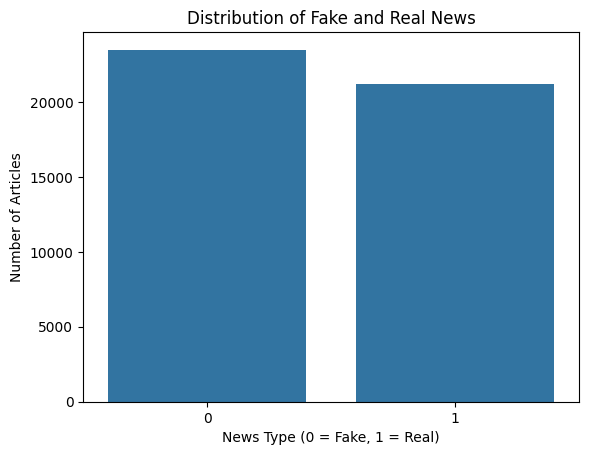

In [11]:
sns.countplot(data=df, x="label")

plt.title("Distribution of Fake and Real News")
plt.xlabel("News Type (0 = Fake, 1 = Real)")
plt.ylabel("Number of Articles")

plt.show()

In [12]:
df["content"] = df["title"] + " " + df["text"]

display(df[["title", "content", "label"]].head())

,title,content,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,Ben Stein Calls Out 9th Circuit Court: Committ...,0
1,Trump drops Steve Bannon from National Securit...,Trump drops Steve Bannon from National Securit...,1
2,Puerto Rico expects U.S. to lift Jones Act shi...,Puerto Rico expects U.S. to lift Jones Act shi...,1
3,OOPS: Trump Just Accidentally Confirmed He Le...,OOPS: Trump Just Accidentally Confirmed He Le...,0
4,Donald Trump heads for Scotland to reopen a go...,Donald Trump heads for Scotland to reopen a go...,1


In [13]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\s+", " ", text)

    return text.strip()

df["content"] = df["content"].apply(clean_text)

display(df[["content", "label"]].head())

,content,label
0,ben stein calls out th circuit court committed...,0
1,trump drops steve bannon from national securit...,1
2,puerto rico expects us to lift jones act shipp...,1
3,oops trump just accidentally confirmed he leak...,0
4,donald trump heads for scotland to reopen a go...,1


In [14]:
X = df["content"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

Training Data: 35751
Testing Data: 8938


In [15]:
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training Feature Shape:", X_train_tfidf.shape)
print("Testing Feature Shape:", X_test_tfidf.shape)

Training Feature Shape: (35751, 5000)
Testing Feature Shape: (8938, 5000)


In [16]:
lr = LogisticRegression(max_iter=1000)

lr.fit(X_train_tfidf, y_train)

lr_pred = lr.predict(X_test_tfidf)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_pred) * 100)

Logistic Regression Accuracy: 98.90355784291788


In [17]:
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train_tfidf, y_train)

dt_pred = dt.predict(X_test_tfidf)


rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_tfidf, y_train)

rf_pred = rf.predict(X_test_tfidf)

print("Decision Tree Accuracy:",
      accuracy_score(y_test, dt_pred) * 100)

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred) * 100)

Decision Tree Accuracy: 99.48534347728798
Random Forest Accuracy: 99.83217722085477


In [19]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_tfidf, y_train)

knn_pred = knn.predict(X_test_tfidf)

print("KNN Accuracy:",
      accuracy_score(y_test, knn_pred) * 100)

KNN Accuracy: 71.64913850973372


In [20]:
models = {
    "Logistic Regression": lr_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "KNN": knn_pred
}

results = []

for name, prediction in models.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction),
        "Recall": recall_score(y_test, prediction),
        "F1 Score": f1_score(y_test, prediction)
    })

results_df = pd.DataFrame(results)

display(results_df.sort_values(
    by="F1 Score",
    ascending=False
))

,Model,Accuracy,Precision,Recall,F1 Score
2,Random Forest,0.998322,0.997645,0.998821,0.998233
1,Decision Tree,0.994853,0.995747,0.993399,0.994572
0,Logistic Regression,0.989036,0.984792,0.992221,0.988492
3,KNN,0.716491,0.935270,0.432579,0.591554


Best Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4696
           1       1.00      1.00      1.00      4242

    accuracy                           1.00      8938
   macro avg       1.00      1.00      1.00      8938
weighted avg       1.00      1.00      1.00      8938



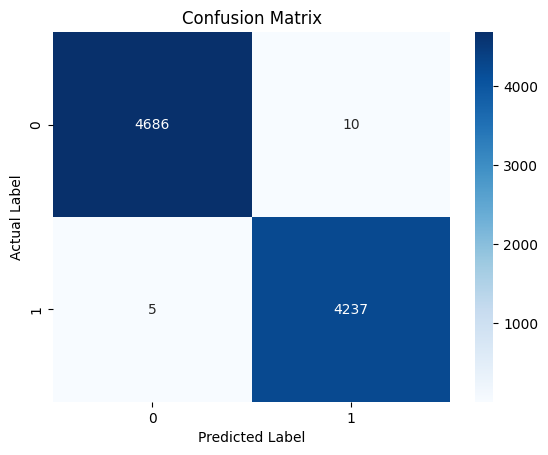

In [21]:
best_name = results_df.sort_values(
    by="F1 Score",
    ascending=False
).iloc[0]["Model"]

best_prediction = models[best_name]

print("Best Model:", best_name)

print("\nClassification Report:")
print(classification_report(y_test, best_prediction))

cm = confusion_matrix(y_test, best_prediction)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [22]:
import joblib

best_models = {
    "Logistic Regression": lr,
    "Decision Tree": dt,
    "Random Forest": rf,
    "KNN": knn
}

final_model = best_models[best_name]

def predict_news(news):

    cleaned_news = clean_text(news)

    news_tfidf = tfidf.transform([cleaned_news])

    prediction = final_model.predict(news_tfidf)[0]

    if prediction == 0:
        print("Prediction: FAKE NEWS")
    else:
        print("Prediction: REAL NEWS")


sample_news = "The government announced a new policy today."

predict_news(sample_news)

joblib.dump(
    {"model": final_model, "tfidf": tfidf},
    "fake_news_detection_model.pkl"
)

print("Model saved successfully!")

Prediction: FAKE NEWS
Model saved successfully!
